<a href="https://colab.research.google.com/github/Pathikrit003/Cervical-Cancer-/blob/main/ensemble_sipakmed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIPaKMeD ensemble: EVA-02 + BEiTv2 + ConvNeXtV2



Methods compared (all scored on the **test** set):
1. The 3 individual models
2. Soft voting: average the probabilities
3. Hard voting: majority vote
4. Weighted average: weights tuned on the **validation** set
5. Stacking: a small logistic regression trained on the **validation** set

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, log_loss, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

IN_DIR = "/content/drive/MyDrive/sipakmed_outputs"
OUT_DIR = os.path.join(IN_DIR, "ensemble")
os.makedirs(OUT_DIR, exist_ok=True)

MODELS = ["eva02", "beitv2", "convnextv2"]
CLASS_NAMES = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
EPS = 1e-7

In [ ]:
needed = ["val_labels.npy", "test_labels.npy"] + \
         [f"{m}_{s}_probs.npy" for m in MODELS for s in ("val", "test")]
all_ok = True
for f in needed:
    ok = os.path.exists(os.path.join(IN_DIR, f))
    all_ok &= ok
    print(("OK       " if ok else "MISSING  ") + f)

if not all_ok:
    print("\nStop here: finish the missing training notebook(s) first.")
    print("Search your Drive with:  !find /content/drive/MyDrive -name '*_probs.npy'")

OK       val_labels.npy
OK       test_labels.npy
OK       eva02_val_probs.npy
OK       eva02_test_probs.npy
OK       beitv2_val_probs.npy
OK       beitv2_test_probs.npy
OK       convnextv2_val_probs.npy
OK       convnextv2_test_probs.npy


In [ ]:
val_labels = np.load(os.path.join(IN_DIR, "val_labels.npy"))
test_labels = np.load(os.path.join(IN_DIR, "test_labels.npy"))
val_p = {m: np.load(os.path.join(IN_DIR, f"{m}_val_probs.npy")) for m in MODELS}
test_p = {m: np.load(os.path.join(IN_DIR, f"{m}_test_probs.npy")) for m in MODELS}

for m in MODELS:
    assert val_p[m].shape[0] == len(val_labels), f"{m}: val size mismatch"
    assert test_p[m].shape[0] == len(test_labels), f"{m}: test size mismatch"

print(f"Val images: {len(val_labels)} | Test images: {len(test_labels)}\n")
for m in MODELS:
    print(f"{m:11s} val acc = {accuracy_score(val_labels, val_p[m].argmax(1))*100:.2f}% | "
          f"test acc = {accuracy_score(test_labels, test_p[m].argmax(1))*100:.2f}%")

Val images: 486 | Test images: 810

eva02       val acc = 99.18% | test acc = 98.27%
beitv2      val acc = 99.18% | test acc = 97.16%
convnextv2  val acc = 98.15% | test acc = 97.78%


In [ ]:
# Soft Voting

results = {}
rows = []

def metrics(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Method": name, "Test Acc (%)": round(acc * 100, 2),
            "Macro Precision": round(p, 4), "Macro Recall": round(r, 4), "Macro F1": round(f, 4)}

for m in MODELS:
    results[m.upper()] = test_p[m]
    rows.append(metrics(m.upper(), test_labels, test_p[m].argmax(1)))

soft_test = np.mean([test_p[m] for m in MODELS], axis=0)
results["Soft Voting"] = soft_test
rows.append(metrics("Soft Voting (avg)", test_labels, soft_test.argmax(1)))

pd.DataFrame(rows)

,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1
0,EVA02,98.27,0.9829,0.9828,0.9828
1,BEITV2,97.16,0.9727,0.9719,0.9717
2,CONVNEXTV2,97.78,0.9781,0.9780,0.9778
3,Soft Voting (avg),98.15,0.9818,0.9817,0.9815


In [ ]:
# Hard Voting


votes = np.stack([test_p[m].argmax(1) for m in MODELS], axis=1)
vote_counts = np.zeros((len(test_labels), len(CLASS_NAMES)))
for k in range(len(MODELS)):
    vote_counts[np.arange(len(test_labels)), votes[:, k]] += 1
hard_pred = (vote_counts + 1e-3 * soft_test).argmax(1)
rows.append(metrics("Hard Voting (majority)", test_labels, hard_pred))

pd.DataFrame(rows)

,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1
0,EVA02,98.27,0.9829,0.9828,0.9828
1,BEITV2,97.16,0.9727,0.9719,0.9717
2,CONVNEXTV2,97.78,0.9781,0.9780,0.9778
3,Soft Voting (avg),98.15,0.9818,0.9817,0.9815
4,Hard Voting (majority),97.90,0.9793,0.9793,0.9790


In [ ]:
# Weighted Average


best_w, best_ll = None, np.inf
grid = np.arange(0, 1.0001, 0.05)
for w1, w2 in itertools.product(grid, grid):
    w3 = 1.0 - w1 - w2
    if w3 < -1e-9:
        continue
    w = np.array([w1, w2, max(w3, 0.0)])
    blend = sum(wi * val_p[m] for wi, m in zip(w, MODELS))
    ll = log_loss(val_labels, np.clip(blend, EPS, 1), labels=range(len(CLASS_NAMES)))
    if ll < best_ll:
        best_ll, best_w = ll, w

print("Weights tuned on val: " + ", ".join(f"{m}={w:.2f}" for m, w in zip(MODELS, best_w)))

wavg_test = sum(wi * test_p[m] for wi, m in zip(best_w, MODELS))
results["Weighted Avg"] = wavg_test
rows.append(metrics("Weighted Avg (val-tuned)", test_labels, wavg_test.argmax(1)))

pd.DataFrame(rows)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: T

Weights tuned on val: eva02=1.00, beitv2=0.00, convnextv2=0.00


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: T

,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1
0,EVA02,98.27,0.9829,0.9828,0.9828
1,BEITV2,97.16,0.9727,0.9719,0.9717
2,CONVNEXTV2,97.78,0.9781,0.9780,0.9778
3,Soft Voting (avg),98.15,0.9818,0.9817,0.9815
4,Hard Voting (majority),97.90,0.9793,0.9793,0.9790
5,Weighted Avg (val-tuned),98.27,0.9829,0.9828,0.9828


In [ ]:
# Stacking


def stack_features(pdict):
    return np.concatenate([np.log(np.clip(pdict[m], EPS, 1)) for m in MODELS], axis=1)

X_val, X_test = stack_features(val_p), stack_features(test_p)
meta = LogisticRegression(C=1.0, max_iter=2000)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_pred = cross_val_predict(meta, X_val, val_labels, cv=skf)
print(f"Stacking 5-fold CV accuracy on val: {accuracy_score(val_labels, cv_pred)*100:.2f}%")
print(f"Soft voting accuracy on val:        "
      f"{accuracy_score(val_labels, np.mean([val_p[m] for m in MODELS], axis=0).argmax(1))*100:.2f}%")

meta.fit(X_val, val_labels)
stack_test = meta.predict_proba(X_test)
results["Stacking"] = stack_test
rows.append(metrics("Stacking (LogReg on val)", test_labels, stack_test.argmax(1)))

pd.DataFrame(rows)

Stacking 5-fold CV accuracy on val: 99.38%
Soft voting accuracy on val:        99.18%


,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1
0,EVA02,98.27,0.9829,0.9828,0.9828
1,BEITV2,97.16,0.9727,0.9719,0.9717
2,CONVNEXTV2,97.78,0.9781,0.9780,0.9778
3,Soft Voting (avg),98.15,0.9818,0.9817,0.9815
4,Hard Voting (majority),97.90,0.9793,0.9793,0.9790
5,Weighted Avg (val-tuned),98.27,0.9829,0.9828,0.9828
6,Stacking (LogReg on val),98.40,0.9842,0.9841,0.9840


In [ ]:
table = pd.DataFrame(rows)
table.to_csv(os.path.join(OUT_DIR, "ensemble_comparison.csv"), index=False)
table

,Method,Test Acc (%),Macro Precision,Macro Recall,Macro F1
0,EVA02,98.27,0.9829,0.9828,0.9828
1,BEITV2,97.16,0.9727,0.9719,0.9717
2,CONVNEXTV2,97.78,0.9781,0.9780,0.9778
3,Soft Voting (avg),98.15,0.9818,0.9817,0.9815
4,Hard Voting (majority),97.90,0.9793,0.9793,0.9790
5,Weighted Avg (val-tuned),98.27,0.9829,0.9828,0.9828
6,Stacking (LogReg on val),98.40,0.9842,0.9841,0.9840


Validation scores: {'Soft Voting': 99.18, 'Weighted Avg': 99.18, 'Stacking': 99.38}

Final ensemble chosen on VAL: Stacking
Its test accuracy: 98.40%

                          precision    recall  f1-score   support

            Dyskeratotic     0.9938    0.9877    0.9908       163
            Koilocytotic     0.9873    0.9455    0.9659       165
             Metaplastic     0.9632    0.9874    0.9752       159
               Parabasal     1.0000    1.0000    1.0000       157
Superficial-Intermediate     0.9765    1.0000    0.9881       166

                accuracy                         0.9840       810
               macro avg     0.9842    0.9841    0.9840       810
            weighted avg     0.9841    0.9840    0.9839       810



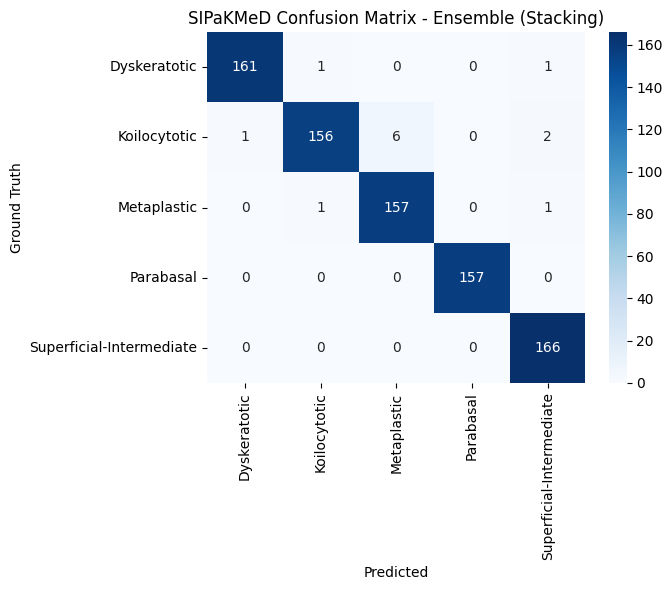

In [ ]:
val_scores = {
    "Soft Voting": accuracy_score(val_labels, np.mean([val_p[m] for m in MODELS], axis=0).argmax(1)),
    "Weighted Avg": accuracy_score(val_labels, sum(w * val_p[m] for w, m in zip(best_w, MODELS)).argmax(1)),
    "Stacking": accuracy_score(val_labels, cv_pred),
}
print("Validation scores:", {k: round(v * 100, 2) for k, v in val_scores.items()})

final_name = max(val_scores, key=val_scores.get)
final_prob = results[final_name]
final_pred = final_prob.argmax(1)
print(f"\nFinal ensemble chosen on VAL: {final_name}")
print(f"Its test accuracy: {accuracy_score(test_labels, final_pred)*100:.2f}%\n")
print(classification_report(test_labels, final_pred, target_names=CLASS_NAMES, digits=4))

np.save(os.path.join(OUT_DIR, "ensemble_test_probs.npy"), final_prob)

cm = confusion_matrix(test_labels, final_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"SIPaKMeD Confusion Matrix - Ensemble ({final_name})")
plt.xlabel("Predicted")
plt.ylabel("Ground Truth")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ensemble_confusion_matrix.png"), dpi=300)
plt.show()

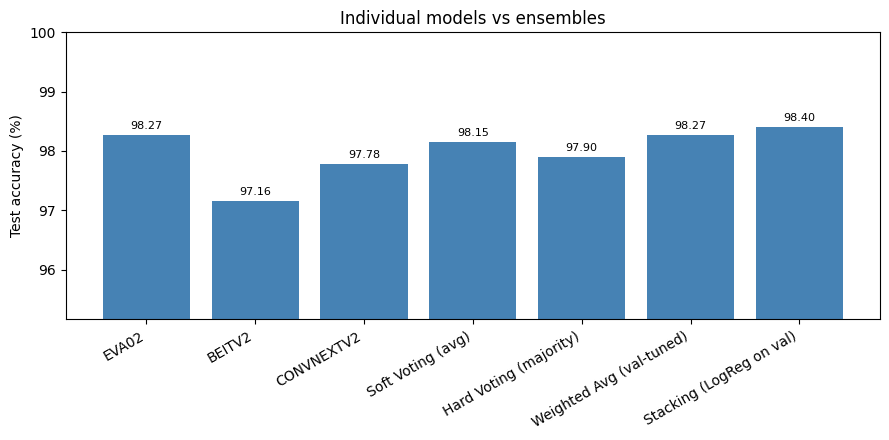

Everything saved to: /content/drive/MyDrive/sipakmed_outputs/ensemble


In [ ]:
plt.figure(figsize=(9, 4.5))
plt.bar(table["Method"], table["Test Acc (%)"], color="steelblue")
plt.ylim(max(0, table["Test Acc (%)"].min() - 2), 100)
plt.xticks(rotation=30, ha="right")
plt.ylabel("Test accuracy (%)")
plt.title("Individual models vs ensembles")
for i, v in enumerate(table["Test Acc (%)"]):
    plt.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "ensemble_accuracy_bar.png"), dpi=300)
plt.show()

print("Everything saved to:", OUT_DIR)